# 21 · Efecto de la cuantización: EmoGol-2B en 4, 8 y 16 bits

El informe de evaluación pide analizar el compromiso entre la cuantización del modelo y su desempeño. EmoGol-2B se entrenó con QLoRA sobre el modelo base en 4 bits (NF4) y se evaluó así. Este notebook aplica **el mismo adaptador**, sin volver a entrenar, sobre el modelo base cargado de tres formas:

- **4 bits (NF4):** la configuración evaluada y la del prototipo.
- **8 bits (LLM.int8):** cuantización intermedia.
- **16 bits (float16):** sin cuantizar.

Las tres se comparan sobre los mismos 2.000 comentarios de la prueba (semilla 42): accuracy y F1 macro con intervalo *bootstrap*, respuestas inválidas, comentarios por segundo en lotes de 16, latencia uno a uno y memoria de GPU. El adaptador aprendió sobre los pesos en 4 bits, de modo que en 8 y 16 bits trabaja sobre pesos un poco distintos de los del entrenamiento; ese es justamente el efecto que se mide.

**Entorno:** Google Colab con GPU T4. **Duración:** unos 45 minutos (8 bits es la más lenta). **Secretos:** `HF_TOKEN`.
**Resultado:** tabla y gráfica en `emotion-futbol-data/final/cuantizacion/`.

In [1]:
!pip install -q -U transformers accelerate peft bitsandbytes "huggingface_hub<2.0" "pandas<3" joblib scikit-learn
!pip uninstall -y -q torchao
!rm -rf emotion_futbol && git clone -q https://github.com/santiagortegasegura/emotion_futbol.git
!pip install -q -e emotion_futbol/emogol_app

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for emogol (pyproject.toml) ... done


In [2]:
import os, sys, gc, time, json
sys.path.insert(0, "/content/emotion_futbol/emogol_app")  # el paquete instalado con -e no se ve hasta reiniciar el entorno
import numpy as np, pandas as pd, torch, joblib
from google.colab import userdata
from huggingface_hub import login, hf_hub_download
from sklearn.metrics import f1_score

os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
login(token=os.environ["HF_TOKEN"])
REPO_MODELO = "santiagortegasegura/emogol-2b"
REPO_DATOS = "santiagortegasegura/emotion-futbol-data"
EMOCIONES = ['alegria', 'tristeza', 'enojo', 'miedo', 'sorpresa', 'burla', 'neutral']

prueba = pd.read_csv(hf_hub_download(REPO_DATOS, "final/prueba_final_10k.csv", repo_type="dataset"), keep_default_na=False)
muestra = prueba.sample(2000, random_state=42).reset_index(drop=True)
ruta_joblib = hf_hub_download(REPO_MODELO, "emogol.joblib")
print(f"Muestra: {len(muestra)} comentarios | GPU {torch.cuda.get_device_name(0)}")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


prueba_final_10k.csv:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

emogol.joblib: reconstructing file:   0%|          |  0.00B / 46.6MB            

emogol.joblib: downloading bytes:           |  0.00B            

Muestra: 2000 comentarios | GPU Tesla T4


## Evaluar cada configuración

In [3]:
def bootstrap(y, p, n=1000, semilla=42):
    rng = np.random.default_rng(semilla)
    y, p = np.array(y), np.array(p)
    accs, f1s = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        accs.append((y[i] == p[i]).mean())
        f1s.append(f1_score(y[i], p[i], labels=EMOCIONES, average="macro", zero_division=0))
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])

def evaluar(bits):
    emogol = joblib.load(ruta_joblib)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); emogol.cargar(bits=bits); carga = time.time() - t0
    memoria_modelo = torch.cuda.memory_allocated() / 2**20
    emogol.calentar()
    # latencia uno a uno
    lat = []
    for texto in muestra["text"][:50]:
        torch.cuda.synchronize(); t = time.perf_counter()
        emogol.predecir([texto]); torch.cuda.synchronize()
        lat.append(time.perf_counter() - t)
    # lote de 16 sobre los 2.000 comentarios
    torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    pred = emogol.predecir(muestra["text"].tolist())
    torch.cuda.synchronize(); segundos = time.time() - t
    y = muestra["label"].tolist()
    ic_acc, ic_f1 = bootstrap(y, pred)
    fila = {"bits": bits,
            "accuracy": float(np.mean(np.array(pred) == np.array(y))), "accuracy_ic95": [round(float(v), 4) for v in ic_acc],
            "f1_macro": float(f1_score(y, pred, labels=EMOCIONES, average="macro", zero_division=0)),
            "f1_macro_ic95": [round(float(v), 4) for v in ic_f1],
            "invalidas_pct": 100 * float(np.mean(np.array(pred) == "invalido")),
            "comentarios_por_s": len(pred) / segundos, "latencia_uno_a_uno_s": float(np.median(lat)),
            "memoria_modelo_mib": memoria_modelo, "memoria_pico_mib": torch.cuda.max_memory_allocated() / 2**20,
            "segundos_carga": carga}
    del emogol; gc.collect(); torch.cuda.empty_cache()
    return fila, pred

filas, predicciones = [], {}
for bits in (4, 16, 8):
    fila, pred = evaluar(bits)
    filas.append(fila); predicciones[bits] = pred
    print(f"{bits:>2} bits | acc {fila['accuracy']:.3f} | F1 macro {fila['f1_macro']:.3f} | inválidas {fila['invalidas_pct']:.1f} % | "
          f"{fila['comentarios_por_s']:.2f} com/s | uno a uno {fila['latencia_uno_a_uno_s']:.2f} s | "
          f"memoria modelo {fila['memoria_modelo_mib']:.0f} MiB | pico {fila['memoria_pico_mib']:.0f} MiB")
tabla = pd.DataFrame(filas).sort_values("bits").reset_index(drop=True)
tabla

config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/24.2k [00:00<?, ?B/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.


 8 bits | acc 0.846 | F1 macro 0.788 | inválidas 0.0 % | 4.41 com/s | uno a uno 3.18 s | memoria modelo 3147 MiB | pico 3572 MiB


,bits,accuracy,accuracy_ic95,f1_macro,f1_macro_ic95,invalidas_pct,comentarios_por_s,latencia_uno_a_uno_s,memoria_modelo_mib,memoria_pico_mib,segundos_carga
0,4,0.8500,"[0.834, 0.866]",0.807813,"[0.7436, 0.8505]",0.0,3.974979,0.762497,2202.623047,2631.973145,80.147254
1,8,0.8455,"[0.829, 0.8615]",0.788053,"[0.7299, 0.8308]",0.0,4.406343,3.177674,3146.561523,3572.408203,12.564763
2,16,0.8460,"[0.8305, 0.8615]",0.793801,"[0.7351, 0.8337]",0.0,4.111574,0.608893,5073.807617,5497.609863,16.371005


## ¿Cambian las predicciones?

Se compara cada configuración con la de 4 bits: cuántos comentarios reciben la misma emoción y, con la prueba de McNemar, si la diferencia de aciertos es significativa.

In [4]:
from math import erf, sqrt
y = np.array(muestra["label"])
base = np.array(predicciones[4])
comparacion = []
for bits in (8, 16):
    p = np.array(predicciones[bits])
    b = int(((base == y) & (p != y)).sum()); c_ = int(((base != y) & (p == y)).sum())
    chi2 = (abs(b - c_) - 1) ** 2 / (b + c_) if b + c_ else 0.0
    valor_p = 2 * (1 - 0.5 * (1 + erf(sqrt(chi2) / sqrt(2)))) if chi2 else 1.0
    comparacion.append({"frente_a_4_bits": bits, "misma_emocion_pct": 100 * float((p == base).mean()),
                        "solo_4_bits_acierta": b, "solo_esta_acierta": c_, "chi2": round(chi2, 3), "p": round(valor_p, 4)})
comparacion = pd.DataFrame(comparacion)
comparacion

,frente_a_4_bits,misma_emocion_pct,solo_4_bits_acierta,solo_esta_acierta,chi2,p
0,8,94.85,49,40,0.719,0.3964
1,16,95.20,46,38,0.583,0.4450


## Gráfica y publicación

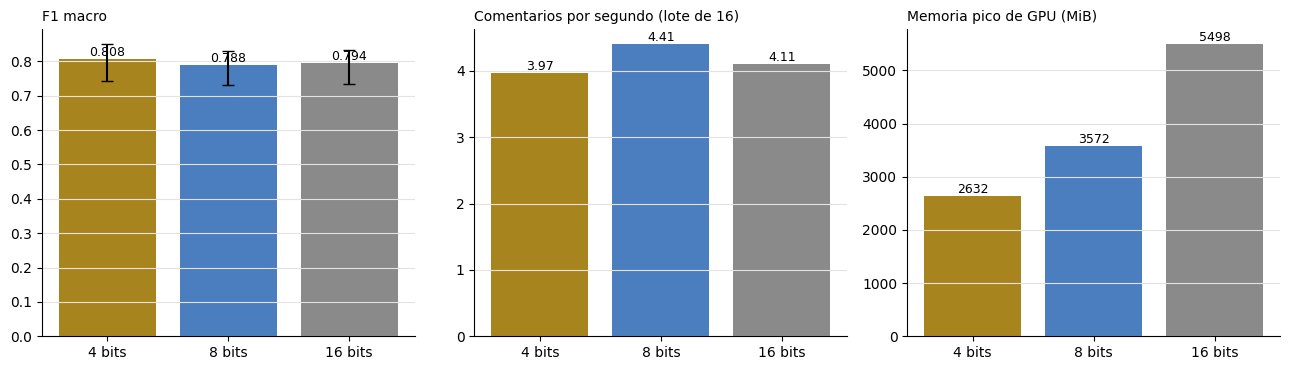

Subido: final/cuantizacion/cuantizacion_resultados.csv
Subido: final/cuantizacion/cuantizacion_comparacion.csv
Subido: final/cuantizacion/cuantizacion_predicciones.csv
Subido: final/cuantizacion/cuantizacion_resumen.json


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/cuantizacion.png   : 100%|##########| 75.2kB / 75.2kB            

Validating                    :           |   0%            

Subido: final/cuantizacion/cuantizacion.png


In [5]:
import matplotlib.pyplot as plt
ORO, AZUL, GRIS, REJILLA = "#A8841F", "#4A7EBF", "#8A8A8A", "#E4E3DF"
etiquetas = [f"{b} bits" for b in tabla["bits"]]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))
datos = [("F1 macro", tabla["f1_macro"], [abs(np.array(v) - f) for v, f in zip(tabla["f1_macro_ic95"], tabla["f1_macro"])]),
         ("Comentarios por segundo (lote de 16)", tabla["comentarios_por_s"], None),
         ("Memoria pico de GPU (MiB)", tabla["memoria_pico_mib"], None)]
for ax, (titulo, valores, error) in zip(ejes, datos):
    yerr = np.array(error).T if error is not None else None
    ax.bar(etiquetas, valores, color=[ORO, AZUL, GRIS], yerr=yerr, capsize=4)
    for i, v in enumerate(valores):
        ax.text(i, v, f"{v:.3f}" if titulo.startswith("F1") else f"{v:.2f}" if "segundo" in titulo else f"{v:.0f}",
                ha="center", va="bottom", fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=10); ax.grid(axis="y", color=REJILLA); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("cuantizacion.png", dpi=200); plt.show()

from huggingface_hub import upload_file
tabla.to_csv("cuantizacion_resultados.csv", index=False)
comparacion.to_csv("cuantizacion_comparacion.csv", index=False)
pd.DataFrame({"text": muestra["text"], "label": muestra["label"], **{f"pred_{b}_bits": predicciones[b] for b in (4, 8, 16)}}) \
  .to_csv("cuantizacion_predicciones.csv", index=False)
json.dump({"gpu": torch.cuda.get_device_name(0), "n": len(muestra), "resultados": filas,
           "comparacion": comparacion.to_dict(orient="records")},
          open("cuantizacion_resumen.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
for archivo in ["cuantizacion_resultados.csv", "cuantizacion_comparacion.csv", "cuantizacion_predicciones.csv",
                "cuantizacion_resumen.json", "cuantizacion.png"]:
    upload_file(path_or_fileobj=archivo, path_in_repo=f"final/cuantizacion/{archivo}", repo_id=REPO_DATOS, repo_type="dataset")
    print(f"Subido: final/cuantizacion/{archivo}")